In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import os
os.chdir("/home/tomas/Escritorio/CD/tp7")
import utils
os.chdir("/home/tomas/Escritorio/CD/tp7/ej4")


In [19]:
utils.descarga("https://ignaciorlando.github.io/datasets/data-science/datospractico6csdatos.xlsx", "datospractico6csdatos.xlsx", 4)

In [2]:
df = pd.read_excel("datospractico6csdatos.xlsx", sheet_name="Proteins")

In [47]:
df

,País,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,Frutas yVegetales
0,Albania,"10,10","1,40","0,50","8,90","0,20","42,30","0,60","5,50","1,70"
1,Austria,"8,90","14,00","4,30","19,90","2,10","28,00","3,60","1,30","4,30"
2,Bélgica,"13,50","9,30","4,10","17,50","4,50","26,60","5,70","2,10","4,00"
3,Bulgaria,"7,80","6,00","1,60","8,30","1,20","56,70","1,10","3,70","4,20"
4,Checosl,"9,70","11,40","2,80","12,50","2,00","34,30","5,00","1,10","4,00"
5,Dinamarca,"10,60","10,80","3,70","25,00","9,90","21,90","4,80","0,70","2,40"
6,AlemaniaE,"8,40","11,60","3,70","11,10","5,40","24,60","6,50","0,80","3,60"
7,Finlandia,"9,50","4,90","2,70","33,70","5,80","26,30","5,10","1,00","1,40"
8,Francia,"18,00","9,90","3,30","19,50","5,70","28,10","4,80","2,40","6,50"
9,Grecia,"10,20","3,00","2,80","17,60","5,90","41,70","2,20","7,80","6,50"


<h3>Inciso a

In [3]:
columnas = df.columns.drop("País")
for i in columnas:
    if df[i].dtype != "number":
        df[i] = df[i].str.replace(",", ".")
        df[i] = pd.to_numeric(df[i], errors="coerce")

In [4]:
df.describe(include = "all").drop(["count", "unique"], axis = 0)

,País,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,Frutas yVegetales
top,Albania,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,NaN,9.828000,7.896000,2.936000,17.112000,4.284000,32.248000,4.276000,3.072000,4.136000
std,NaN,3.347078,3.694081,1.117617,7.105416,3.402533,10.974786,1.634085,1.985682,1.803903
min,NaN,4.400000,1.400000,0.500000,4.900000,0.200000,18.600000,0.600000,0.700000,1.400000
25%,NaN,7.800000,4.900000,2.700000,11.100000,2.100000,24.300000,3.100000,1.500000,2.900000
50%,NaN,9.500000,7.800000,2.900000,17.600000,3.400000,28.000000,4.700000,2.400000,3.800000
75%,NaN,10.600000,10.800000,3.700000,23.300000,5.800000,40.100000,5.700000,4.700000,4.900000
max,NaN,18.000000,14.000000,4.700000,33.700000,14.200000,56.700000,6.500000,7.800000,7.900000


<Axes: >

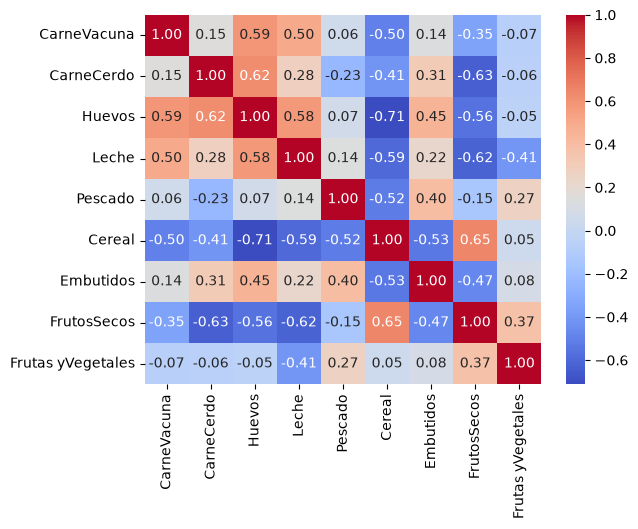

In [5]:
correlation_matrix = df.select_dtypes(include="number").corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")

Tras la obtencion de datos, podemos notar como el alimento con mayor consumicion es el cereal pero tambien con un gran desvio estandar entre los paises que lo consumen. Luego, entre los alimentos menos consumidos tenemos a los huevos y frutos secos. Finalmente, podemos notar correlaciones fuertes dadas por los pares (CarneCerdo, huevos), (CarneCerdo, FrutosSecos), (Huevos, Cereal)

<h3>Inciso b

In [6]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_scaled = scaler.fit_transform(df.select_dtypes(include="number"))

In [7]:
from sklearn.decomposition import PCA

In [8]:
pca = PCA(n_components=2, whiten=False)
principalComponents = pca.fit_transform(df_scaled)

In [9]:
print(pca.explained_variance_ratio_.sum())

0.6268263356549788


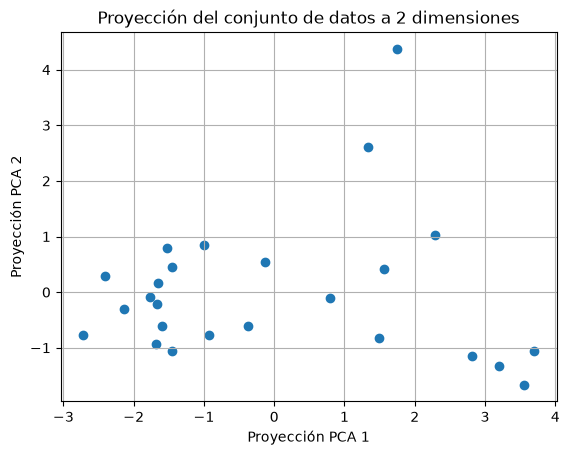

In [10]:
#graficamos cada punto mediante un scatter plot, donde cada punto es un registro del dataset
plt.scatter(principalComponents[:,0], principalComponents[:,1])
plt.grid(True)
plt.xlabel('Proyección PCA 1')
plt.ylabel('Proyección PCA 2')
plt.title('Proyección del conjunto de datos a 2 dimensiones')
plt.show()

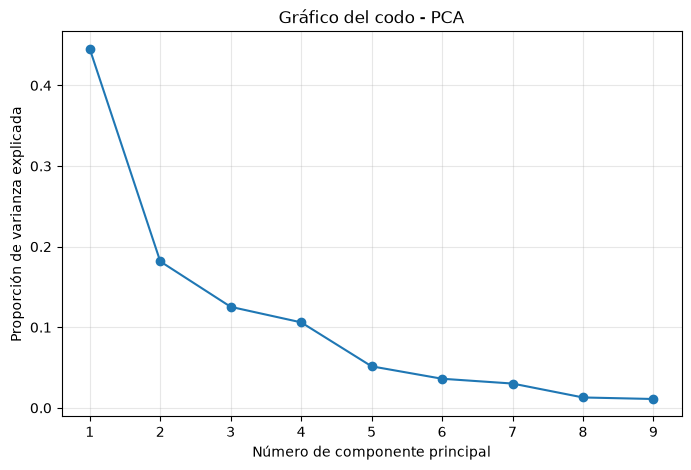

In [11]:
pca_codo = PCA()
pca_codo.fit(df_scaled)
# Varianza explicada por cada componente
varianza = pca_codo.explained_variance_ratio_

# Gráfico del codo
plt.figure(figsize=(8, 5))
plt.plot(
    range(1, len(varianza) + 1),
    varianza,
    marker="o"
)

plt.xlabel("Número de componente principal")
plt.ylabel("Proporción de varianza explicada")
plt.title("Gráfico del codo - PCA")
plt.xticks(range(1, len(varianza) + 1))
plt.grid(True, alpha=0.3)
plt.show()

In [12]:
print(f"Varianza explicada por los primeros 3 componentes: {pca_codo.explained_variance_ratio_[0:3].sum():.2f}")
print(f"Varianza explicada por los primeros 5 componentes: {pca_codo.explained_variance_ratio_[0:5].sum():.2f}")

Varianza explicada por los primeros 3 componentes: 0.75
Varianza explicada por los primeros 5 componentes: 0.91


<h3>Inciso c

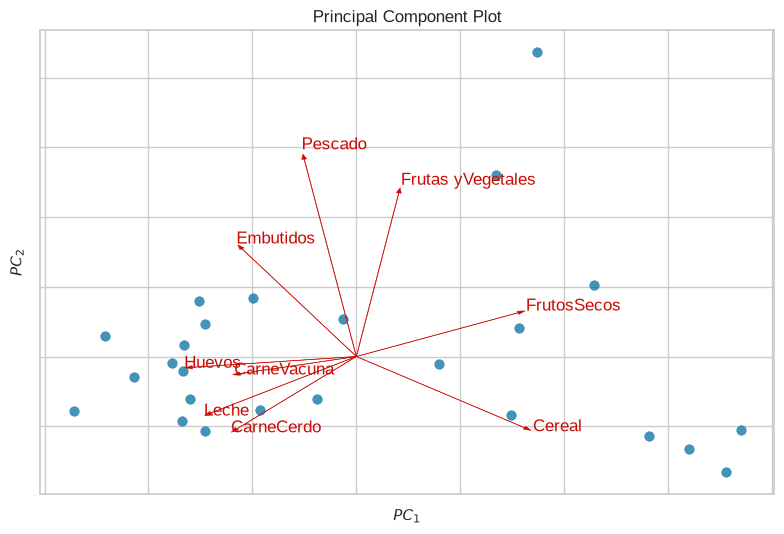

<Axes: title={'center': 'Principal Component Plot'}, xlabel='$PC_1$', ylabel='$PC_2$'>

In [13]:
from yellowbrick.features import PCA as PcaViz

# declaramos un objeto de la clase PcaViz:
viz = PcaViz(
    scale=True,          # le vamos a pedir que estandarice (si le pasáramos datos estandarizados esto va en false)
    proj_features=True,  # le pedimos que dibuje las proyecciones de la features originales
    projection=2,        # le pedimos dos proyecciones
)
# lo aplicamos sobre los datos originales
df_viz = df.select_dtypes(include="number")
viz.fit_transform(df_viz)
# y pedimos que se grafique
viz.show()

In [14]:
loadings = pd.DataFrame(
    viz.pca_components_.T,
    index=df.select_dtypes(include="number").columns,
    columns=["PC1", "PC2"]
)

print(loadings.sort_values("PC1", ascending=False))

                        PC1       PC2
Cereal             0.437743 -0.233485
FrutosSecos        0.420334  0.143311
Frutas yVegetales  0.110420  0.536190
Pescado           -0.135650  0.646820
Embutidos         -0.297248  0.352826
CarneVacuna       -0.302609 -0.056252
CarneCerdo        -0.310556 -0.236853
Leche             -0.377727 -0.184589
Huevos            -0.426679 -0.035336


- Podemos ver como el Cereal y los frutos secos son los que mas contribuyen a la componente 1 donde el resto, sacando el pescado, aporta negativamente a la misma componente.

- Podemos ver como los que aportan a la componente con mayor fuerza son el pescado y las frutas / vegetales donde, sacando los embutidos y frutos secos, el resto aporta negativamente a la misma componente.

- Ademas, podemos ver como los huevos y carne vacuna tienen una relacion alta entre ambas.

- Podemos ver como el huevo, carne vacuna, leche y carne de cerdo tienen una relacion negativa alta con los frutos secos.

- Finalmente, vemos relaciones practicamente nulas por la ortoganilidad de los pares de variables (pescado, leche), (pescado, carne de cerdo), (pescado, frutos secos) y (frutas / vegetales, cereal)

<h3>Inciso d

<Axes: >

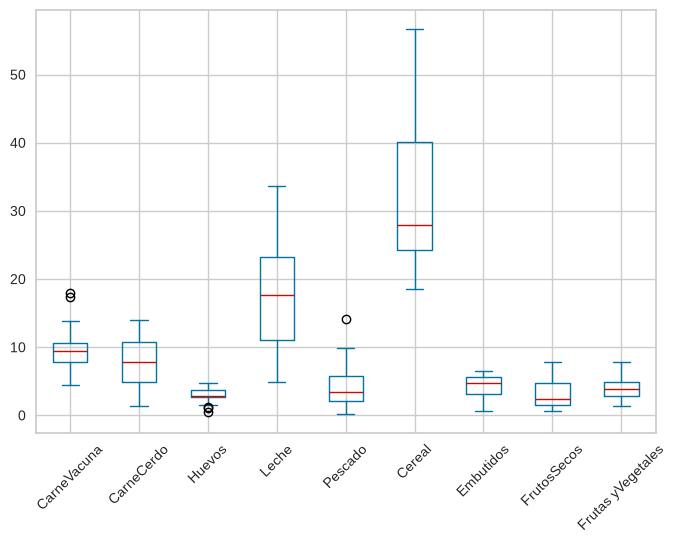

In [22]:
df.plot(kind="box", rot=45)

In [ ]:
plt.boxplot(df_scaled)
plt.xlabel("Features")
plt.ylabel("Values")
plt.title("Boxplot of Scaled Features")
plt.xticks(ticks=range(1, len(df.select_dtypes(include="number").columns) + 1), labels=df.select_dtypes(include="number").columns, rotation=45)
plt.show()

In [16]:
df["Pescado"].describe()

count    25.000000
mean      4.284000
std       3.402533
min       0.200000
25%       2.100000
50%       3.400000
75%       5.800000
max      14.200000
Name: Pescado, dtype: float64

In [17]:
df[["País", "Pescado"]].sort_values(by="Pescado", ascending=False)

,País,Pescado
16,Portugal,14.2
5,Dinamarca,9.9
14,Noruega,9.7
19,Suecia,7.5
18,España,7.0
9,Grecia,5.9
7,Finlandia,5.8
8,Francia,5.7
6,AlemaniaE,5.4
2,Bélgica,4.5


<function matplotlib.pyplot.show(close=None, block=None)>

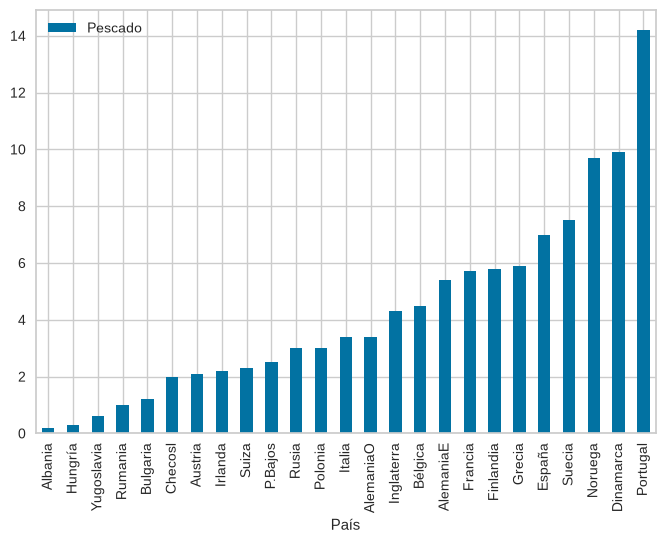

In [27]:
df.sort_values(by="Pescado", ascending=True).plot(
    kind="bar",
    x="País",
    y="Pescado"
)
plt.show

Podemos ver que el consumo de pescado esta descripto por una media de 4.28 donde el desvio es de 3.4. Ademas, notamos que el 50% del consumo del pescado se encuentra entre 2.1 y 5.8. Ademas, tenemos que paises como Portugal, Dinamarca y Noruega son los que mas consumen este alimento, teniendo sentido estos 2 ultimos por ser paises nordicos y, paises como Yugoslavia, Hungria, y Albania son aquellos que tienen el menor consumo de pescado

<h3>Inciso e

<Axes: xlabel='País'>

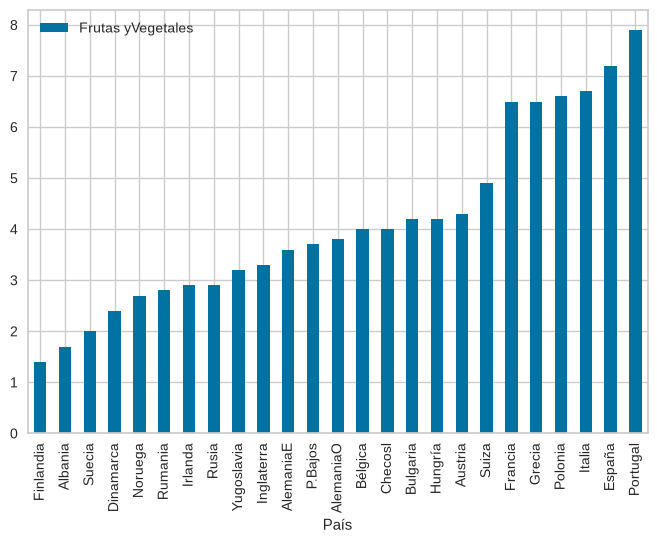

In [28]:
df.sort_values(by="Frutas yVegetales", ascending=True).plot(
    kind="bar",
    x="País",
    y="Frutas yVegetales"
)

Podemos ver que paises como Portugal, España e Italia son aquellos paises con mayor consumicion de frutas y verduras

<h3>Inciso f

In [30]:
df_f = df[df["País"].isin(["Portugal", "España", "Italia"])]

In [31]:
df_f

,País,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,Frutas yVegetales
12,Italia,9.0,5.1,2.9,13.7,3.4,36.8,2.1,4.3,6.7
16,Portugal,6.2,3.7,1.1,4.9,14.2,27.0,5.9,4.7,7.9
18,España,7.1,3.4,3.1,8.6,7.0,29.2,5.7,5.9,7.2


In [32]:
df_f.describe()

,CarneVacuna,CarneCerdo,Huevos,Leche,Pescado,Cereal,Embutidos,FrutosSecos,Frutas yVegetales
count,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000,3.000000
mean,7.433333,4.066667,2.366667,9.066667,8.200000,31.000000,4.566667,4.966667,7.266667
std,1.429452,0.907377,1.101514,4.418522,5.499091,5.141984,2.138535,0.832666,0.602771
min,6.200000,3.400000,1.100000,4.900000,3.400000,27.000000,2.100000,4.300000,6.700000
25%,6.650000,3.550000,2.000000,6.750000,5.200000,28.100000,3.900000,4.500000,6.950000
50%,7.100000,3.700000,2.900000,8.600000,7.000000,29.200000,5.700000,4.700000,7.200000
75%,8.050000,4.400000,3.000000,11.150000,10.600000,33.000000,5.800000,5.300000,7.550000
max,9.000000,5.100000,3.100000,13.700000,14.200000,36.800000,5.900000,5.900000,7.900000


Podemos ver como estos paises se diferencian principalmente en el consumo de leche, pescado y cereal. Ademas, tenemos que Portugal lidera el consumo de alimentos como pescado, embutidos y frutas / vegetales. Por otro lado, italia lidera consumo de alimentos como carne vacuna, carne de cerdo, leche y cereales. Finalmente, España lidera consumo de alimentos como huevos y frutos secos